# Quickstart: discovering a hidden miscalibration field

Calibration is usually checked in aggregate: across all inputs with confidence about 0.7, is the model right about 70% of the time? A model can pass that check while being **overconfident on some inputs and underconfident on others**, with the errors cancelling out.

The *miscalibration field* makes that structure explicit:

$$\delta(x) = \mathbb{E}[\,Y - f(X) \mid X = x\,]$$

Here $f(x)$ is the model's confidence and $Y \in \{0, 1\}$ is whether it was correct. $\delta(x) < 0$ means accuracy is below confidence (overconfident) near $x$; $\delta(x) > 0$ means underconfident. This package learns a representation $\phi(x)$ in which kernel-averaging the residuals $y_i - f(x_i)$ gives a good estimate $\hat\delta_\phi(x)$, using only observed $(x, f, y)$ triples, with no predefined groups.

This notebook runs on a CPU in about a minute, on a synthetic dataset where the true field is known:
1. generate the data,
2. train $\phi$,
3. estimate the field and compare it with the truth,
4. split the data into over-, well- and underconfident regions,
5. correct confidence locally, and compare against confidence-only recalibration.

In [1]:
import json, subprocess, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import LinearSegmentedColormap
from sklearn.isotonic import IsotonicRegression

from calib_atlas.data.dataset import DATASETS_DIR
from calib_atlas.field import estimate_field, load_run, make_run_loaders
from calib_atlas.models.baselines import TemperatureScaler
from calib_atlas.utils.eval_utils import (
    apply_range_aware_correction,
    fit_range_aware_scale,
    get_smece,
    plot_binned_relplot,
)

REPO = Path.cwd().resolve().parent  # notebooks/ lives in the repository root
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
FIELD_CMAP = LinearSegmentedColormap.from_list("field", ["steelblue", "lightgray", "salmon"])
REGION_COLORS = {"over": "steelblue", "good": "gray", "under": "salmon"}


def run(*args):
    """Run a command from the repository root and print the last lines of its log (minus progress bars)."""
    res = subprocess.run([sys.executable, *args], cwd=REPO, capture_output=True, text=True)
    lines = [l for l in (res.stdout + res.stderr).splitlines() if l.strip() and "it/s" not in l and "%|" not in l]
    print("\n".join(lines[-8:]).replace(str(REPO), "."))
    res.check_returncode()

## 1. Data

Inputs $x \in \mathbb{R}^2$ come from three Gaussian clusters. The confidence $f(x)$ has the same distribution in every cluster, but the true probability of being correct is shifted **down** in one cluster (overconfident), left unchanged in another (well calibrated), and shifted **up** in the third (underconfident). The data generator writes a Hugging Face dataset with columns `emb` ($x$), `f`, `y`, plus the ground truth (`eta` $=P(Y=1\mid x)$, so the true field is `eta - f`).

In [2]:
data_path = Path(DATASETS_DIR) / "synthetic_3_clusters"
if not data_path.exists():
    run("-m", "calib_atlas.data.generate_synthetic_data", "clusters", "--out_dir", DATASETS_DIR)

from datasets import load_from_disk
ds = load_from_disk(str(data_path)).with_format("numpy")[:]  # dict of numpy arrays
x, f, y, true_delta = ds["emb"], ds["f"], ds["y"], ds["eta"] - ds["f"]
print(f"{len(f)} examples; mean confidence {f.mean():.3f}, accuracy {y.mean():.3f}")

10000 examples; mean confidence 0.502, accuracy 0.499


The aggregate reliability diagram looks almost perfectly calibrated. The scatter plot shows why that's misleading: the true field differs sharply between clusters.

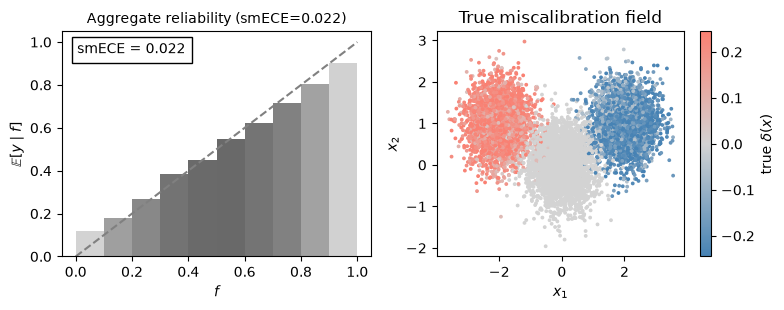

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3.2))
plot_binned_relplot(f, y, n_bins=10, fig=fig, ax=axs[0])
axs[0].set_title(f"Aggregate reliability (smECE={get_smece(f, y):.3f})", fontsize=10)
lim = np.abs(true_delta).max()
sc = axs[1].scatter(x[:, 0], x[:, 1], c=true_delta, cmap=FIELD_CMAP, vmin=-lim, vmax=lim, s=3)
fig.colorbar(sc, ax=axs[1], label=r"true $\delta(x)$")
axs[1].set(title="True miscalibration field", xlabel="$x_1$", ylabel="$x_2$")
plt.tight_layout(); plt.show()

## 2. Train $\phi$

Training is a Hydra command-line program (`python -m calib_atlas.train`), configured by `configs/config.yaml`. The two key hyperparameters are the kernel bandwidth `loss.sigma` and the mass regularizer `loss.lambda_mass`. The checkpoint lands in `outputs/synthetic_3_clusters/quickstart/`.

In [4]:
run_dir = REPO / "outputs" / "synthetic_3_clusters" / "quickstart"
run(
    "-m", "calib_atlas.train", "--config-name=config",
    "+data.path=synthetic_3_clusters", "++model.in_dim=2",
    "++loss.sigma=0.1", "++loss.lambda_mass=1e-3", "++trainer.epochs=30",
    f"++device={DEVICE}", "run_name=quickstart",
)

Epoch 24 | val/corrected_bs_score = 0.19192
Epoch 25 | val/corrected_bs_score = 0.19192
Epoch 26 | val/corrected_bs_score = 0.19193
Epoch 27 | val/corrected_bs_score = 0.19195
Epoch 28 | val/corrected_bs_score = 0.19196
Epoch 29 | val/corrected_bs_score = 0.19197
Best val/corrected_bs_score (min): 0.1919
Artifacts saved to: ./outputs/synthetic_3_clusters/quickstart


## 3. Estimate the field

`load_run` restores $\phi$ and the run's config. `make_run_loaders` rebuilds the same train/val/test split used in training. `estimate_field` kernel-smooths the training residuals in $\phi$-space at every query point.

In [5]:
phi, cfg = load_run(run_dir, device=DEVICE)
loaders = make_run_loaders(cfg)
test = estimate_field(phi, cfg, bank_loader=loaders["train"], query_loader=loaders["test"])
val = estimate_field(phi, cfg, bank_loader=loaders["train"], query_loader=loaders["val"])
test = {k: v.cpu() if torch.is_tensor(v) else v for k, v in test.items()}
val = {k: v.cpu() if torch.is_tensor(v) else v for k, v in val.items()}

t_true = (test["eta"] - test["f"]).numpy()
t_hat = test["hat_delta"].numpy()
print(f"correlation between estimated and true field on the test split: {np.corrcoef(t_true, t_hat)[0, 1]:.3f}")

correlation between estimated and true field on the test split: 0.956


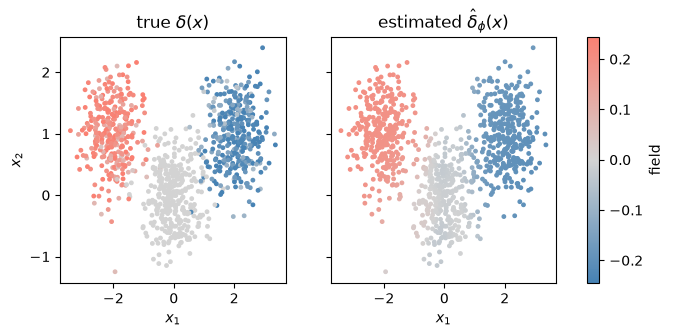

In [6]:
xt = test["emb"].numpy()
lim = max(np.abs(t_true).max(), np.abs(t_hat).max())
fig, axs = plt.subplots(1, 2, figsize=(8, 3.2), sharex=True, sharey=True)
for ax, val_, title in [(axs[0], t_true, r"true $\delta(x)$"), (axs[1], t_hat, r"estimated $\hat\delta_\phi(x)$")]:
    sc = ax.scatter(xt[:, 0], xt[:, 1], c=val_, cmap=FIELD_CMAP, vmin=-lim, vmax=lim, s=6)
    ax.set(title=title, xlabel="$x_1$")
axs[0].set_ylabel("$x_2$")
fig.colorbar(sc, ax=axs, label="field")
plt.show()

## 4. Regions of over- and underconfidence

Thresholding $\hat\delta_\phi$ splits the data into regions that the field says are overconfident ($\hat\delta_\phi < -t$), well calibrated, or underconfident ($\hat\delta_\phi > t$). The reliability diagram of each region shows the error that the aggregate diagram hid.

In [7]:
def regions(hat_delta, t):
    """over: field < -t (accuracy below confidence); under: field > t; good: in between."""
    h = np.asarray(hat_delta)
    return np.where(h < -t, "over", np.where(h > t, "under", "good"))

In [8]:
def region_relplots(f, y, region, n_bins=10):
    names = ["all", "over", "good", "under"]
    fig, axs = plt.subplots(1, 4, figsize=(11, 2.8), sharey=True)
    for ax, name in zip(axs, names):
        m = np.ones_like(region, dtype=bool) if name == "all" else region == name
        if m.sum() == 0:
            ax.set_visible(False)
            continue
        cmap = None if name == "all" else LinearSegmentedColormap.from_list(name, ["lightgray", REGION_COLORS[name]])
        plot_binned_relplot(f[m], y[m], n_bins=n_bins, cmap=cmap, fig=fig, ax=ax)
        ax.set_title(f"{name}  (n={m.sum()})", fontsize=10)
        if ax is not axs[0]:
            ax.set_ylabel("")
    plt.tight_layout()
    plt.show()

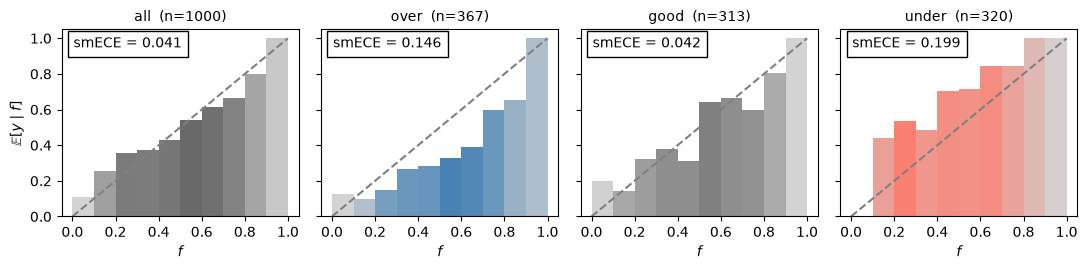

In [9]:
T = 0.05
test_region = regions(t_hat, T)
region_relplots(test["f"].numpy(), test["y"].numpy(), test_region)

## 5. Local confidence correction

The field also says *how* to fix confidence: move it down where $\hat\delta_\phi<0$ and up where $\hat\delta_\phi>0$. The correction

$$\tilde f(x) = f(x) + \begin{cases}(1-f(x))\tanh(\alpha\,|\hat\delta_\phi(x)|) & \hat\delta_\phi(x) \ge 0\\ -f(x)\tanh(\alpha\,|\hat\delta_\phi(x)|) & \hat\delta_\phi(x) < 0\end{cases}$$

stays inside $[0, 1]$ and has a single strength $\alpha$, fitted on the validation split. Temperature scaling and isotonic regression can only remap confidence as a function of $f$ itself. Because the aggregate curve was already nearly calibrated, they have almost nothing to fix, and the regional errors stay.

In [10]:
def correct(val, test):
    """Fit every recalibration map on the validation split, apply it to the test split."""
    fv, yv, hv = val["f"].numpy(), val["y"].numpy(), val["hat_delta"].numpy()
    ft = test["f"].numpy()
    alpha = fit_range_aware_scale(fv, yv, hv)  # strength of the local, field-based correction
    ts = TemperatureScaler().fit(fv, yv)
    iso = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds="clip").fit(fv, yv)
    return {
        "uncorrected": ft,
        "temperature": np.asarray(ts.predict_proba(ft)),
        "isotonic": iso.predict(ft),
        "field (ours)": apply_range_aware_correction(test["f"], test["hat_delta"], alpha).numpy(),
    }

In [11]:
def compare_by_region(y, region, preds):
    """smECE and Brier score of each prediction column, overall and per region."""
    rows = []
    for name in ["all", "over", "good", "under"]:
        m = np.ones_like(region, dtype=bool) if name == "all" else region == name
        if m.sum() == 0:
            continue
        for method, p in preds.items():
            rows.append({"region": name, "n": int(m.sum()), "method": method,
                         "smECE": get_smece(p[m], y[m]), "Brier": float(np.mean((p[m] - y[m]) ** 2))})
    df = pd.DataFrame(rows)
    return df.pivot_table(index=["region", "n"], columns="method", values=["smECE", "Brier"], sort=False).round(4)

In [12]:
preds = correct(val, test)
compare_by_region(test["y"].numpy(), test_region, preds)["smECE"]

,method,uncorrected,temperature,isotonic,field (ours)
region,n,,,,
all,1000,0.0409,0.0281,0.0262,0.0318
over,367,0.1460,0.1421,0.1501,0.0478
good,313,0.0416,0.0377,0.0370,0.0349
under,320,0.1988,0.1945,0.1991,0.0407


## Next steps

* **`02_llm_case_study.ipynb`** repeats this analysis for a real LLM: Qwen3-8B-Base judging HH-RLHF response pairs.
* To use your own model, see *Using your own model* in the README: save `(emb, f, y)` as a Hugging Face dataset under `datasets/<name>` and train with `+data.path=<name>`.